# CSET485 – AI and Society · Assignment 1
## Stress-testing a credit-approval model: German Credit Data (Statlog)

| Item | Value |
|---|---|
| Enrollment number (last 4 digits) | **0095** |
| Assigned dataset (last digit = 5 → 3/4/5) | **German Credit Data (UCI Statlog)** |
| Random seed (last 3 digits = 095) | **`random_state = 95`** |
| Train / test split | 70 % / 30 % (stratified on the outcome) |
| Outcome | `approve` = 1 if the applicant is a *good* credit risk (UCI class 1), 0 if *bad* (UCI class 2) |

**How to reproduce:** `pip install -r requirements.txt`, then *Kernel → Restart & Run All*.
The notebook downloads `german.data` from UCI; if the download fails it uses the identical copy in `data/german.data`
(content checks are asserted below). Every number in the PDF report is written to `results/results.json`
and the tables in `results/*.csv`; every chart is saved to `figures/`.

**Contents**
0. Setup and data loading
1. Data preprocessing (missing values, encoding, scaling, outliers)
2. Part 1 – Model A (OLS) vs Model B (logistic): threshold comparison
3. Part 2.1 – Simpson's-paradox hunt
4. Part 2.2 – Omitted-variable bias
5. Part 2.3 – Adversarial subset (confident, wrong predictions)
6. Part 2.4 – Fairness trade-off sweep
7. Export of all results

In [1]:
# ---------- 0. Setup ----------
import os, json, hashlib, urllib.request, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from scipy import stats
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegressionCV
from sklearn.metrics import roc_auc_score, accuracy_score

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)

ROLL_LAST4 = "0095"
assert int(ROLL_LAST4[-1]) in (3, 4, 5), "last digit 3/4/5 -> German Credit"
SEED = int(ROLL_LAST4[-3:])          # '095' -> 95
print("Random seed:", SEED)

os.makedirs("figures", exist_ok=True); os.makedirs("results", exist_ok=True); os.makedirs("data", exist_ok=True)
R = {"seed": SEED, "roll_last4": ROLL_LAST4}      # every reported number is collected here

# Plot style (validated categorical palette: blue / orange / aqua; muted ink for text)
C1, C2, C3, INK, MUTED, GRID = "#2a78d6", "#eb6834", "#1baf7a", "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "font.size": 10, "axes.edgecolor": MUTED,
                     "axes.labelcolor": INK, "xtick.color": MUTED, "ytick.color": MUTED,
                     "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.color": GRID, "grid.linewidth": 0.8, "axes.titleweight": "bold",
                     "axes.titlesize": 11, "legend.frameon": False})
def r(x, k=3):
    "round helper for the results file"
    return None if x is None or (isinstance(x, float) and np.isnan(x)) else round(float(x), k)

Random seed: 95


### 0.1 Load the raw data
UCI file: 1,000 applicants × 20 attributes + class, space-separated, attribute values coded `A11…A202`.

In [2]:
UCI_URL = "https://archive.ics.uci.edu/ml/machine-learning-databases/statlog/german/german.data"
LOCAL = "data/german.data"

def get_raw():
    try:
        raw = urllib.request.urlopen(UCI_URL, timeout=30).read(); src = "UCI download"
        if not os.path.exists(LOCAL):
            open(LOCAL, "wb").write(raw)
    except Exception as e:
        print("UCI download unavailable (", type(e).__name__, ") -> using bundled copy", LOCAL)
        raw = open(LOCAL, "rb").read(); src = "bundled copy of UCI german.data"
    print("Source:", src, "| bytes:", len(raw), "| md5:", hashlib.md5(raw).hexdigest())
    return raw

COLS = ["checking_status", "duration", "credit_history", "purpose", "credit_amount", "savings_status",
        "employment", "installment_rate", "personal_status", "other_parties", "residence_since", "property",
        "age", "other_payment_plans", "housing", "existing_credits", "job", "num_dependents",
        "own_telephone", "foreign_worker", "class"]
from io import StringIO
raw = pd.read_csv(StringIO(get_raw().decode("ascii")), sep=r"\s+", header=None, names=COLS)

# content checks: these are the published properties of the UCI file
assert raw.shape == (1000, 21)
assert raw["class"].value_counts().to_dict() == {1: 700, 2: 300}
assert raw["credit_amount"].sum() == 3271258 and abs(raw["age"].mean() - 35.546) < 1e-9
print(raw.shape); raw.head(3)

UCI download unavailable ( URLError ) -> using bundled copy data/german.data
Source: bundled copy of UCI german.data | bytes: 79793 | md5: 6b94c2e35480e671545e52a808a8a549
(1000, 21)


,checking_status,duration,credit_history,purpose,credit_amount,savings_status,employment,installment_rate,personal_status,other_parties,residence_since,property,age,other_payment_plans,housing,existing_credits,job,num_dependents,own_telephone,foreign_worker,class
0,A11,6,A34,A43,1169,A65,A75,4,A93,A101,4,A121,67,A143,A152,2,A173,1,A192,A201,1
1,A12,48,A32,A43,5951,A61,A73,2,A92,A101,2,A121,22,A143,A152,1,A173,1,A191,A201,2
2,A14,12,A34,A46,2096,A61,A74,2,A93,A101,3,A121,49,A143,A152,1,A172,2,A191,A201,1


## 1. Data preprocessing

### 1.1 Decoding the categorical codes and defining the outcome
The 13 qualitative attributes are mapped from UCI codes to readable labels (from `german.doc`).
`approve = 1` for class 1 (*good* risk) and `0` for class 2 (*bad* risk), as required by the brief.
Two analysis variables are derived for Parts 2.1 and 2.4 (they are **not** extra model features):
`sex` (from `personal_status`: A92/A95 = female) and `young` (age ≤ 25, the conventional split for this dataset).

In [3]:
MAPS = {
 "checking_status": {"A11": "lt0", "A12": "0to200", "A13": "ge200", "A14": "none"},
 "credit_history": {"A30": "no_credits_all_paid", "A31": "all_paid_this_bank", "A32": "existing_paid",
                    "A33": "delayed_past", "A34": "critical_other"},
 "purpose": {"A40": "car_new", "A41": "car_used", "A42": "furniture", "A43": "radio_tv", "A44": "appliances",
             "A45": "repairs", "A46": "education", "A47": "vacation", "A48": "retraining", "A49": "business",
             "A410": "other"},
 "savings_status": {"A61": "lt100", "A62": "100to500", "A63": "500to1000", "A64": "ge1000", "A65": "unknown_none"},
 "employment": {"A71": "unemployed", "A72": "lt1", "A73": "1to4", "A74": "4to7", "A75": "ge7"},
 "personal_status": {"A91": "male_div_sep", "A92": "female_div_sep_mar", "A93": "male_single",
                     "A94": "male_mar_wid", "A95": "female_single"},
 "other_parties": {"A101": "none", "A102": "co_applicant", "A103": "guarantor"},
 "property": {"A121": "real_estate", "A122": "life_insurance", "A123": "car_other", "A124": "unknown_none"},
 "other_payment_plans": {"A141": "bank", "A142": "stores", "A143": "none"},
 "housing": {"A151": "rent", "A152": "own", "A153": "for_free"},
 "job": {"A171": "unemp_unskilled_nonres", "A172": "unskilled_res", "A173": "skilled", "A174": "mgmt_selfemp_highqual"},
 "own_telephone": {"A191": "no", "A192": "yes"},
 "foreign_worker": {"A201": "yes", "A202": "no"},
}
# reference (dropped) level for each one-hot block = most common or most interpretable baseline
REF = {"checking_status": "lt0", "credit_history": "existing_paid", "purpose": "radio_tv", "savings_status": "lt100",
       "employment": "1to4", "personal_status": "male_single", "other_parties": "none", "property": "real_estate",
       "other_payment_plans": "none", "housing": "own", "job": "skilled", "own_telephone": "no", "foreign_worker": "yes"}
CAT = list(MAPS)
NUM_RAW = ["duration", "credit_amount", "installment_rate", "residence_since", "age", "existing_credits", "num_dependents"]

df = raw.copy()
for c, m in MAPS.items():
    df[c] = df[c].map(m)
    assert df[c].notna().all(), c        # every code mapped
df["approve"] = (df["class"] == 1).astype(int)
df = df.drop(columns="class")
df["sex"] = np.where(df["personal_status"].isin(["female_div_sep_mar", "female_single"]), "female", "male")
df["young"] = (df["age"] <= 25).astype(int)
R["n_rows"] = len(df); R["approve_rate_all"] = r(df.approve.mean())
R["n_female"] = int((df.sex == "female").sum()); R["n_young"] = int(df.young.sum())
R["approve_rate_by_sex"] = {k: r(v) for k, v in df.groupby("sex").approve.mean().items()}
R["approve_rate_by_young"] = {("young_le25" if k else "older_gt25"): r(v) for k, v in df.groupby("young").approve.mean().items()}
print(R["approve_rate_by_sex"], R["approve_rate_by_young"])
df.head()

{'female': 0.648, 'male': 0.723} {'older_gt25': 0.728, 'young_le25': 0.579}


,checking_status,duration,credit_history,purpose,credit_amount,savings_status,employment,installment_rate,personal_status,other_parties,residence_since,property,age,other_payment_plans,housing,existing_credits,job,num_dependents,own_telephone,foreign_worker,approve,sex,young
0,lt0,6,critical_other,radio_tv,1169,unknown_none,ge7,4,male_single,none,4,real_estate,67,none,own,2,skilled,1,yes,yes,1,male,0
1,0to200,48,existing_paid,radio_tv,5951,lt100,1to4,2,female_div_sep_mar,none,2,real_estate,22,none,own,1,skilled,1,no,yes,0,female,1
2,none,12,critical_other,education,2096,lt100,4to7,2,male_single,none,3,real_estate,49,none,own,1,unskilled_res,2,no,yes,1,male,0
3,lt0,42,existing_paid,furniture,7882,lt100,4to7,2,male_single,guarantor,4,life_insurance,45,none,for_free,1,skilled,2,no,yes,1,male,0
4,lt0,24,delayed_past,car_new,4870,lt100,1to4,3,male_single,none,4,unknown_none,53,none,for_free,2,skilled,2,no,yes,0,male,0


### 1.2 Missing values
The UCI file has no blank cells and no `?` placeholders. The categories *"unknown / no savings account"* (A65) and
*"unknown / no property"* (A124) are genuine response categories, so they are **kept as their own levels** rather than imputed.

In [4]:
miss = pd.DataFrame({"n_missing (NaN)": raw.isna().sum(),
                     "n_'?'_placeholders": (raw.astype(str) == "?").sum()})
R["n_missing_total"] = int(miss.values.sum())
print("Total missing cells:", R["n_missing_total"])
R["female_single_count"] = int((df.personal_status == "female_single").sum())
R["n_savings_unknown"] = int((df.savings_status == "unknown_none").sum())
R["n_property_unknown"] = int((df.property == "unknown_none").sum())
R["n_checking_none"] = int((df.checking_status == "none").sum())
print("A95 (female single) rows in data:", R["female_single_count"])
miss.T

Total missing cells: 0
A95 (female single) rows in data: 0


,checking_status,duration,credit_history,purpose,credit_amount,savings_status,employment,installment_rate,personal_status,other_parties,residence_since,property,age,other_payment_plans,housing,existing_credits,job,num_dependents,own_telephone,foreign_worker,class
n_missing (NaN),0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
n_'?'_placeholders,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0


### 1.3 Outliers (IQR rule) and the decision taken
Values outside [Q1 − 1.5·IQR, Q3 + 1.5·IQR] are flagged. They are all plausible (e.g., a 72-month loan, DM 18,424, age 75),
so **no rows are removed** (n = 1,000 is small and the flagged rows are disproportionately bad risks).
`credit_amount` (skew ≈ 1.95) is **log-transformed** to reduce the leverage of the long right tail; `num_dependents` is
binary-like (1 or 2), so its IQR "outliers" are an artefact of the rule, not true outliers.

In [5]:
rows = []
for c in NUM_RAW:
    q1, q3 = df[c].quantile([.25, .75]); iqr = q3 - q1; lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_out = int(((df[c] < lo) | (df[c] > hi)).sum())
    rows.append({"feature": c, "min": df[c].min(), "Q1": q1, "median": df[c].median(), "Q3": q3, "max": df[c].max(),
                 "IQR_upper_fence": hi, "n_flagged": n_out, "pct_flagged": round(100 * n_out / len(df), 1),
                 "skew": round(df[c].skew(), 2),
                 "approve_rate_flagged": round(df.loc[(df[c] < lo) | (df[c] > hi), "approve"].mean(), 3) if n_out else np.nan})
outl = pd.DataFrame(rows)
df["log_credit_amount"] = np.log(df["credit_amount"])
R["skew_credit_amount_before"] = r(df.credit_amount.skew(), 2); R["skew_credit_amount_after"] = r(df.log_credit_amount.skew(), 2)
outl.to_csv("results/outliers.csv", index=False)
R["outliers"] = outl.to_dict(orient="records")
print("credit_amount skew before/after log:", R["skew_credit_amount_before"], R["skew_credit_amount_after"])
outl

credit_amount skew before/after log: 1.95 0.13


,feature,min,Q1,median,Q3,max,IQR_upper_fence,n_flagged,pct_flagged,skew,approve_rate_flagged
0,duration,4,12.0,18.0,24.00,72,42.000,70,7.0,1.09,0.429
1,credit_amount,250,1365.5,2319.5,3972.25,18424,7882.375,72,7.2,1.95,0.458
2,installment_rate,1,2.0,3.0,4.00,4,7.000,0,0.0,-0.53,NaN
3,residence_since,1,2.0,3.0,4.00,4,7.000,0,0.0,-0.27,NaN
4,age,19,27.0,33.0,42.00,75,64.500,23,2.3,1.02,0.739
5,existing_credits,1,1.0,1.0,2.00,4,3.500,6,0.6,1.27,0.667
6,num_dependents,1,1.0,1.0,1.00,2,1.000,155,15.5,1.91,0.703


### 1.4 Train/test split, categorical encoding and feature scaling
* **Split:** 70/30, `random_state = 95`, stratified on `approve` so both parts keep the 70 % approval base rate.
* **Encoding:** one-hot (dummy) encoding of the 13 qualitative attributes with the reference level dropped (avoids the dummy
  trap; each coefficient is a contrast against the reference). Ordered-looking categories (checking, savings, employment) are
  also one-hot encoded because their levels are not equally spaced and include *"none/unknown"*. Levels absent from the data
  (A95 female-single, A47 vacation) produce no column.
* **Scaling:** the 7 numeric features (`duration`, `log_credit_amount`, `installment_rate`, `residence_since`, `age`,
  `existing_credits`, `num_dependents`) are z-scored with the **training-set** mean and SD (no test-set leakage);
  dummies are left as 0/1. Numeric coefficients therefore read as "per 1 SD".

In [6]:
NUM = ["duration", "log_credit_amount", "installment_rate", "residence_since", "age", "existing_credits", "num_dependents"]
tr_idx, te_idx = train_test_split(df.index, test_size=0.30, random_state=SEED, stratify=df["approve"])
tr_idx, te_idx = pd.Index(sorted(tr_idx)), pd.Index(sorted(te_idx))
MU, SD = df.loc[tr_idx, NUM].mean(), df.loc[tr_idx, NUM].std(ddof=0)

def design(d):
    "numeric z-scores (train mean/SD) + one-hot dummies with reference level dropped"
    parts = [(d[NUM] - MU) / SD]
    for c in CAT:
        for lvl in MAPS[c].values():
            if lvl != REF[c] and (df[c] == lvl).any():
                parts.append(pd.Series((d[c] == lvl).astype(float), index=d.index, name=f"{c}={lvl}"))
    return pd.concat(parts, axis=1)

X = design(df); y = df["approve"]; XC = sm.add_constant(X)
Xtr, Xte, ytr, yte = XC.loc[tr_idx], XC.loc[te_idx], y.loc[tr_idx], y.loc[te_idx]
R.update(n_train=len(tr_idx), n_test=len(te_idx), n_features=X.shape[1],
         approve_rate_train=r(ytr.mean()), approve_rate_test=r(yte.mean()),
         n_bad_train=int((ytr == 0).sum()), age_sd_train=r(SD["age"], 2), age_mean_train=r(MU["age"], 2),
         epv_train=r((ytr == 0).sum() / X.shape[1], 2), n_dummies=int(X.shape[1] - len(NUM)))
pd.DataFrame({"train_mean": MU, "train_sd": SD}).round(3).to_csv("results/scaling.csv")
print({k: R[k] for k in ["n_train", "n_test", "n_features", "approve_rate_train", "approve_rate_test", "epv_train"]})

{'n_train': 700, 'n_test': 300, 'n_features': 48, 'approve_rate_train': 0.7, 'approve_rate_test': 0.7, 'epv_train': 4.38}


## 2. Part 1 — Build and compare

* **Model A (OLS / linear probability model):** `approve` (0/1) regressed on all 48 features → predicted "probability".
* **Model B (logistic regression, unpenalised MLE):** same features, same training rows.

Test-set rules from the brief: Model A flag = 1 if prediction ≥ **median of Model A's test predictions**; Model B flag = 1 if
P ≥ **0.5**. For German Credit the outcome is *approval*, so "flag = 1" means **predicted good risk / approve**; the rule itself is
applied exactly as written (the "high-risk" wording in the brief is generic across the three datasets).

In [7]:
ols = sm.OLS(ytr, Xtr).fit()
logit = sm.Logit(ytr, Xtr).fit(disp=0, maxiter=500)
assert logit.mle_retvals["converged"]
pA, pB = ols.predict(Xte), logit.predict(Xte)
medA = float(np.median(pA))
flagA, flagB = (pA >= medA).astype(int), (pB >= 0.5).astype(int)

cm = pd.crosstab(flagA.rename("Model A (OLS ≥ median)"), flagB.rename("Model B (logit ≥ 0.5)"))
mism = int((flagA != flagB).sum())
R["p1"] = dict(
    ols_r2=r(ols.rsquared), median_A=r(medA, 4), mean_A=r(pA.mean(), 4), min_A=r(pA.min()), max_A=r(pA.max()),
    n_A_above1=int((pA > 1).sum()), n_A_below0=int((pA < 0).sum()), mean_B=r(pB.mean(), 4), median_B=r(np.median(pB), 4),
    cm={"A0_B0": int(cm.loc[0, 0]), "A0_B1": int(cm.loc[0, 1]), "A1_B0": int(cm.loc[1, 0]), "A1_B1": int(cm.loc[1, 1])},
    n_mismatch=mism, pct_mismatch=r(100 * mism / len(yte), 2), n_agree=int(len(yte) - mism),
    flag_rate_A=r(flagA.mean()), flag_rate_B=r(flagB.mean()),
    spearman=r(stats.spearmanr(pA, pB).statistic, 4), pearson=r(np.corrcoef(pA, pB)[0, 1], 4),
    auc_A=r(roc_auc_score(yte, pA)), auc_B=r(roc_auc_score(yte, pB)),
    acc_A=r(accuracy_score(yte, flagA)), acc_B=r(accuracy_score(yte, flagB)),
    # decomposition: same model family, different cut-offs vs same cut-off rule, different models
    mismatch_same_rule_median=int((flagA != (pB >= np.median(pB)).astype(int)).sum()),
    mismatch_same_cut_05=int(((pA >= 0.5).astype(int) != flagB).sum()),
    pB_range_of_mismatched=[r(pB[flagA != flagB].min()), r(pB[flagA != flagB].max())],
    pA_range_of_mismatched=[r(pA[flagA != flagB].min()), r(pA[flagA != flagB].max())],
    pB_quantile_of_05=r((pB < 0.5).mean()),
)
R["p1"]["pct_mismatch_same_rule_median"] = r(100 * R["p1"]["mismatch_same_rule_median"] / len(yte), 2)
R["p1"]["pct_mismatch_same_cut_05"] = r(100 * R["p1"]["mismatch_same_cut_05"] / len(yte), 2)
cm.to_csv("results/p1_confusion.csv")
print(cm); print({k: v for k, v in R["p1"].items() if k != "cm"})

Model B (logit ≥ 0.5)    0    1
Model A (OLS ≥ median)         
0                       64   86
1                        0  150
{'ols_r2': 0.273, 'median_A': 0.7222, 'mean_A': 0.7261, 'min_A': 0.05, 'max_A': 1.299, 'n_A_above1': 41, 'n_A_below0': 0, 'mean_B': 0.7216, 'median_B': 0.8015, 'n_mismatch': 86, 'pct_mismatch': 28.67, 'n_agree': 214, 'flag_rate_A': 0.5, 'flag_rate_B': 0.787, 'spearman': 0.992, 'pearson': 0.9506, 'auc_A': 0.806, 'auc_B': 0.806, 'acc_A': 0.693, 'acc_B': 0.793, 'mismatch_same_rule_median': 12, 'mismatch_same_cut_05': 8, 'pB_range_of_mismatched': [0.5, 0.859], 'pA_range_of_mismatched': [0.491, 0.721], 'pB_quantile_of_05': 0.213, 'pct_mismatch_same_rule_median': 4.0, 'pct_mismatch_same_cut_05': 2.67}


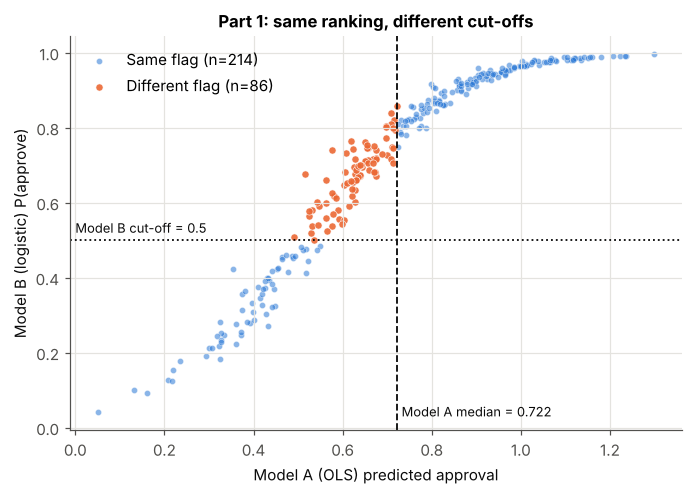

In [8]:
# Figure 1 – where the two rules disagree
fig, ax = plt.subplots(figsize=(6.4, 4.6))
agree = flagA == flagB
ax.scatter(pA[agree], pB[agree], s=16, color=C1, alpha=.55, label=f"Same flag (n={int(agree.sum())})", edgecolor="white", linewidth=.4)
ax.scatter(pA[~agree], pB[~agree], s=22, color=C2, alpha=.9, label=f"Different flag (n={int((~agree).sum())})", edgecolor="white", linewidth=.4)
ax.axvline(medA, color=INK, lw=1.2, ls="--"); ax.axhline(0.5, color=INK, lw=1.2, ls=":")
ax.text(medA + .01, 0.03, f"Model A median = {medA:.3f}", color=INK, fontsize=8.5)
ax.text(0.0, 0.52, "Model B cut-off = 0.5", color=INK, fontsize=8.5)
ax.set_xlabel("Model A (OLS) predicted approval"); ax.set_ylabel("Model B (logistic) P(approve)")
ax.set_title("Part 1: same ranking, different cut-offs"); ax.legend(loc="upper left")
fig.tight_layout(); fig.savefig("figures/fig1_threshold_scatter.png"); plt.show()

## 3. Part 2.1 — Simpson's-paradox hunt

**Split variable:** `sex` (female n = 310 vs male n = 690). **Key predictor:** `age` (z-scored, 1 SD ≈ 11.4 years).
Specification (same in all three fits): age, duration, log credit amount, installment rate, checking-account status (3 dummies),
critical credit history, unknown/no savings. A compact specification is used because the full 48-feature logit does not
converge in the 310-woman subgroup (quasi-separation in sparse dummies) — this is checked below.
The difference between subgroups is tested formally with an `age × female` interaction in the pooled model.

In [9]:
SPEC = ["age", "duration", "log_credit_amount", "installment_rate", "checking_status=0to200", "checking_status=ge200",
        "checking_status=none", "credit_history=critical_other", "savings_status=unknown_none"]
fem = (df.sex == "female")
groups = {"Full (n=1000)": df.index, "Female (n=%d)" % fem.sum(): df.index[fem], "Male (n=%d)" % (~fem).sum(): df.index[~fem]}

# why not the full feature set? -> convergence check in the female subgroup
cols_nops = [c for c in X.columns if not c.startswith("personal_status")]
chk = sm.Logit(y[fem], sm.add_constant(X.loc[fem, cols_nops])).fit(disp=0, maxiter=300)
R["p21_fullspec_female_converged"] = bool(chk.mle_retvals["converged"])
print("48-feature logit converges in female subgroup?", R["p21_fullspec_female_converged"])

fits, rows = {}, []
for g, idx in groups.items():
    m = sm.Logit(y[idx], sm.add_constant(X.loc[idx, SPEC])).fit(disp=0); fits[g] = m
    assert m.mle_retvals["converged"]
    ci = m.conf_int()
    for v in SPEC:
        rows.append({"model": g, "predictor": v, "coef": m.params[v], "ci_low": ci.loc[v, 0], "ci_high": ci.loc[v, 1], "p": m.pvalues[v]})
p21 = pd.DataFrame(rows)
p21.round(4).to_csv("results/p21_coefficients.csv", index=False)
wide = p21.pivot(index="predictor", columns="model", values="coef").loc[SPEC, list(groups)]
print(wide.round(3))

# interaction test: does the age slope differ by sex?
Xi = X[SPEC].copy(); Xi["female"] = fem.astype(float); Xi["age_x_female"] = X["age"] * Xi["female"]
mi = sm.Logit(y, sm.add_constant(Xi)).fit(disp=0); cii = mi.conf_int()

# robustness: age-only model in each group
uni = {g: sm.Logit(y[idx], sm.add_constant(X.loc[idx, ["age"]])).fit(disp=0) for g, idx in groups.items()}

def rec(m, v):
    return {"coef": r(m.params[v], 4), "ci": [r(m.conf_int().loc[v, 0], 4), r(m.conf_int().loc[v, 1], 4)], "p": r(m.pvalues[v], 4),
            "or_per_10y": r(np.exp(m.params[v] / SD["age"] * 10), 3) if v == "age" else None}
keys = list(groups)
R["p21"] = {"full": rec(fits[keys[0]], "age"), "female": rec(fits[keys[1]], "age"), "male": rec(fits[keys[2]], "age"),
            "interaction": {"coef": r(mi.params["age_x_female"], 4), "ci": [r(cii.loc["age_x_female", 0], 4), r(cii.loc["age_x_female", 1], 4)],
                            "p": r(mi.pvalues["age_x_female"], 4)},
            "male_slope_from_interaction_model": r(mi.params["age"], 4),
            "uni_full": rec(uni[keys[0]], "age"), "uni_female": rec(uni[keys[1]], "age"), "uni_male": rec(uni[keys[2]], "age"),
            "n_female": int(fem.sum()), "n_male": int((~fem).sum())}
for k in ["duration", "checking_status=none"]:
    R["p21"]["other_" + k] = {g.split(" ")[0].lower(): r(fits[g].params[k], 3) for g in keys}
print(json.dumps(R["p21"], indent=1)[:1500])

48-feature logit converges in female subgroup? False
model                          Full (n=1000)  Female (n=310)  Male (n=690)
predictor                                                                 
age                                    0.138           0.434        -0.058
duration                              -0.396          -0.492        -0.382
log_credit_amount                     -0.096          -0.036        -0.143
installment_rate                      -0.230          -0.323        -0.226
checking_status=0to200                 0.470           0.165         0.531
checking_status=ge200                  1.037           1.187         0.865
checking_status=none                   1.876           1.690         1.963
credit_history=critical_other          0.764           0.652         0.814
savings_status=unknown_none            0.768           0.537         0.913
{
 "full": {
  "coef": 0.1378,
  "ci": [
   -0.0226,
   0.2982
  ],
  "p": 0.0922,
  "or_per_10y": 1.127
 },
 "female": {


/usr/local/lib/python3.13/dist-packages/statsmodels/discrete/discrete_model.py:268: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


sex       female   male    all
age_band                      
19–25      0.552  0.612  0.579
26–35      0.615  0.740  0.704
36–45      0.810  0.745  0.757
46–75      0.804  0.729  0.747
sex       female  male
age_band              
19–25        105    85
26–35        117   281
36–45         42   184
46–75         46   140


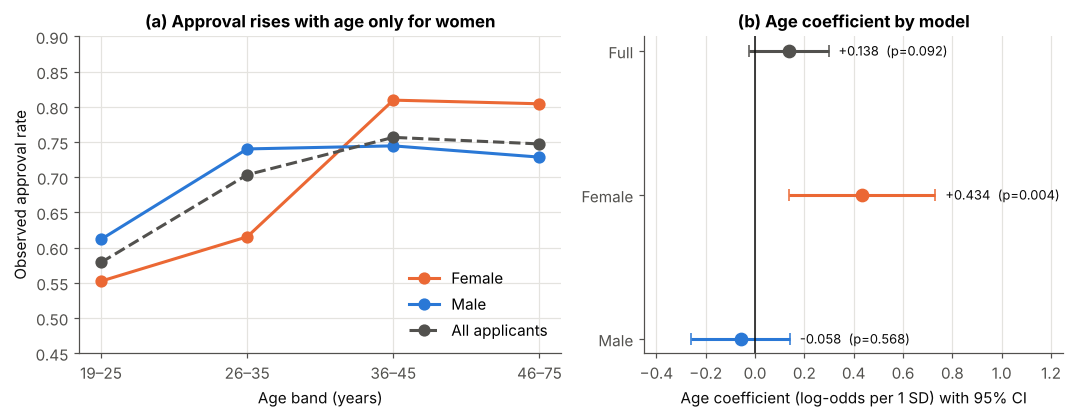

In [10]:
# Why do the slopes differ? Age composition and approval rate by age band within each sex
df["age_band"] = pd.cut(df.age, [18, 25, 35, 45, 80], labels=["19–25", "26–35", "36–45", "46–75"])
band = df.pivot_table(index="age_band", columns="sex", values="approve", aggfunc="mean", observed=False)
band["all"] = df.groupby("age_band", observed=False).approve.mean()
band_n = df.pivot_table(index="age_band", columns="sex", values="approve", aggfunc="size", observed=False)
band.round(3).to_csv("results/p21_ageband_rates.csv"); band_n.to_csv("results/p21_ageband_counts.csv")
R["p21"]["band_rates"] = {s: {str(k): r(v) for k, v in band[s].items()} for s in band.columns}
R["p21"]["band_counts"] = {s: {str(k): int(v) for k, v in band_n[s].items()} for s in band_n.columns}
R["p21"]["median_age"] = {s: r(v, 1) for s, v in df.groupby("sex").age.median().items()}
R["p21"]["share_le25"] = {s: r(v) for s, v in df.groupby("sex").young.mean().items()}
R["p21"]["female_share_of_le25"] = r((df.loc[df.young == 1, "sex"] == "female").mean())
print(band.round(3)); print(band_n)

fig, axes = plt.subplots(1, 2, figsize=(10, 3.9), gridspec_kw={"width_ratios": [1.15, 1]})
ax = axes[0]
for s, col, lab in [("female", C2, "Female"), ("male", C1, "Male"), ("all", MUTED, "All applicants")]:
    ax.plot(band.index.astype(str), band[s].values, marker="o", ms=7, lw=2, color=col, label=lab, ls="--" if s == "all" else "-")
ax.set_ylim(.45, .9); ax.set_ylabel("Observed approval rate"); ax.set_xlabel("Age band (years)")
ax.set_title("(a) Approval rises with age only for women"); ax.legend(loc="lower right")
ax = axes[1]
labs = ["Full", "Female", "Male"]
for i, g in enumerate(keys):
    m = fits[g]; c = m.params["age"]; lo, hi = m.conf_int().loc["age"]
    ax.errorbar(c, i, xerr=[[c - lo], [hi - c]], fmt="o", ms=8, color=[MUTED, C2, C1][i], capsize=4, lw=2)
    ax.text(hi + .04, i, f"{c:+.3f}  (p={m.pvalues['age']:.3f})", va="center", fontsize=8.5, color=INK)
ax.axvline(0, color=INK, lw=1); ax.set_yticks(range(3)); ax.set_yticklabels(labs); ax.invert_yaxis()
ax.set_xlim(-0.45, 1.25); ax.set_xlabel("Age coefficient (log-odds per 1 SD) with 95% CI")
ax.set_title("(b) Age coefficient by model"); ax.grid(axis="y", visible=False)
fig.tight_layout(); fig.savefig("figures/fig2_simpson.png"); plt.show()

## 4. Part 2.2 — Omitted-variable bias

**Dropped variable:** `duration` (loan length in months). It is a textbook confounder of the *credit amount → repayment* link:
longer loans are larger (r ≈ 0.6 with log amount) **and** riskier in their own right.
Both models use all 1,000 rows and the full feature set; the reduced model removes only `duration`.
% change = (reduced − full) / |full| × 100.

In [11]:
full = sm.Logit(y, XC).fit(disp=0, maxiter=500)
red = sm.Logit(y, XC.drop(columns="duration")).fit(disp=0, maxiter=500)
assert full.mle_retvals["converged"] and red.mle_retvals["converged"]
KEY = ["log_credit_amount", "installment_rate", "age", "existing_credits", "checking_status=none",
       "credit_history=critical_other", "purpose=car_used"]
ovb = pd.DataFrame({"coef_full": full.params[KEY], "p_full": full.pvalues[KEY],
                    "coef_reduced": red.params[KEY], "p_reduced": red.pvalues[KEY]})
ovb["abs_shift"] = ovb.coef_reduced - ovb.coef_full
ovb["pct_chg"] = 100 * ovb.abs_shift / ovb.coef_full.abs()
ovb.round(4).to_csv("results/p22_ovb_key.csv")

allc = [c for c in red.params.index if c != "const"]
ovb_all = pd.DataFrame({"coef_full": full.params[allc], "coef_reduced": red.params[allc]})
ovb_all["abs_shift"] = ovb_all.coef_reduced - ovb_all.coef_full
ovb_all["pct_chg"] = 100 * ovb_all.abs_shift / ovb_all.coef_full.abs()
ovb_all.sort_values("abs_shift", key=abs, ascending=False).round(4).to_csv("results/p22_ovb_all.csv")

# OVB mechanics: auxiliary regression of the omitted variable on the remaining features
aux = sm.OLS(X["duration"], sm.add_constant(X.drop(columns="duration"))).fit()
delta = aux.params["log_credit_amount"]
lr_stat = 2 * (full.llf - red.llf)
R["p22"] = {"dropped": "duration",
            "rows": {k: {"full": r(ovb.loc[k, "coef_full"], 4), "red": r(ovb.loc[k, "coef_reduced"], 4),
                         "p_full": r(ovb.loc[k, "p_full"], 4), "p_red": r(ovb.loc[k, "p_reduced"], 4),
                         "shift": r(ovb.loc[k, "abs_shift"], 4), "pct": r(ovb.loc[k, "pct_chg"], 1)} for k in KEY},
            "largest_abs_key": ovb.abs_shift.abs().idxmax(),
            "largest_abs_overall": ovb_all.abs_shift.abs().idxmax(),
            "largest_pct_overall": ovb_all.pct_chg.abs().idxmax(),
            "largest_pct_overall_value": r(ovb_all.pct_chg.abs().max(), 1),
            "largest_pct_overall_base": r(ovb_all.loc[ovb_all.pct_chg.abs().idxmax(), "coef_full"], 4),
            "beta_duration_full": r(full.params["duration"], 4), "p_duration_full": r(full.pvalues["duration"], 6),
            "corr_duration_logamount": r(np.corrcoef(df.duration, df.log_credit_amount)[0, 1], 3),
            "aux_delta": r(delta, 4), "implied_bias": r(full.params["duration"] * delta, 4),
            "auc_full": r(roc_auc_score(y, full.predict(XC))), "auc_red": r(roc_auc_score(y, red.predict(XC.drop(columns="duration")))),
            "llf_full": r(full.llf, 2), "llf_red": r(red.llf, 2), "lr_stat": r(lr_stat, 2), "lr_p": float(stats.chi2.sf(lr_stat, 1)),
            "odds_ratio_amount_full": r(np.exp(full.params["log_credit_amount"]), 3),
            "odds_ratio_amount_red": r(np.exp(red.params["log_credit_amount"]), 3),
            "n_coefs_sign_flip": int((np.sign(ovb_all.coef_full) != np.sign(ovb_all.coef_reduced)).sum())}
print(ovb.round(3)); print({k: v for k, v in R["p22"].items() if k != "rows"})

                               coef_full  p_full  coef_reduced  p_reduced  abs_shift  pct_chg
log_credit_amount                 -0.179   0.205        -0.499      0.000     -0.320 -178.961
installment_rate                  -0.303   0.002        -0.408      0.000     -0.105  -34.709
age                                0.167   0.114         0.191      0.066      0.025   14.800
existing_credits                  -0.162   0.142        -0.136      0.215      0.027   16.514
checking_status=none               1.689   0.000         1.719      0.000      0.029    1.739
credit_history=critical_other      0.856   0.001         0.854      0.001     -0.002   -0.270
purpose=car_used                   0.667   0.081         0.745      0.051      0.078   11.680
{'dropped': 'duration', 'largest_abs_key': 'log_credit_amount', 'largest_abs_overall': 'log_credit_amount', 'largest_pct_overall': 'residence_since', 'largest_pct_overall_value': 815.4, 'largest_pct_overall_base': -0.0012, 'beta_duration_full': -0.

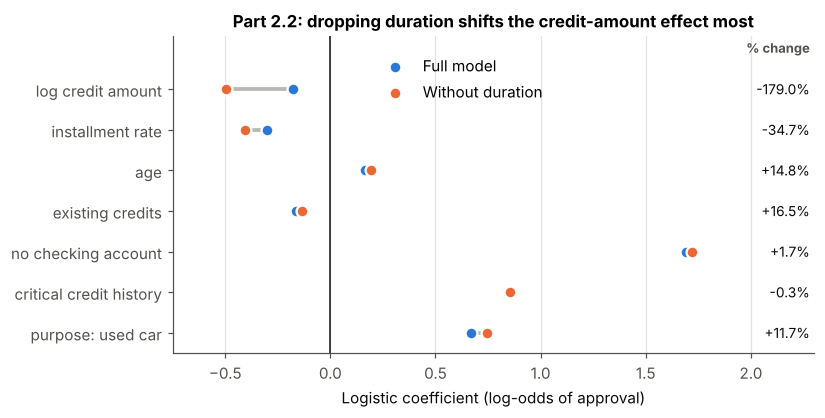

In [12]:
# Figure 3 – before/after coefficients
fig, ax = plt.subplots(figsize=(7.6, 3.9))
labels = {"log_credit_amount": "log credit amount", "installment_rate": "installment rate", "age": "age",
          "existing_credits": "existing credits", "checking_status=none": "no checking account",
          "credit_history=critical_other": "critical credit history", "purpose=car_used": "purpose: used car"}
for i, k in enumerate(KEY):
    a, b = ovb.loc[k, "coef_full"], ovb.loc[k, "coef_reduced"]
    ax.plot([a, b], [i, i], color="#b9b8b3", lw=2.5, zorder=1)
    ax.scatter(a, i, s=60, color=C1, zorder=3, label="Full model" if i == 0 else None, edgecolor="white", linewidth=1.5)
    ax.scatter(b, i, s=60, color=C2, zorder=3, label="Without duration" if i == 0 else None, edgecolor="white", linewidth=1.5)
    ax.text(2.28, i, f"{ovb.loc[k, 'pct_chg']:+.1f}%", va="center", ha="right", fontsize=9, color=INK)
ax.text(2.28, -0.9, "% change", ha="right", fontsize=8.5, color=MUTED, fontweight="bold")
ax.axvline(0, color=INK, lw=1); ax.set_yticks(range(len(KEY))); ax.set_yticklabels([labels[k] for k in KEY]); ax.set_ylim(len(KEY) - 0.5, -1.3)
ax.set_xlabel("Logistic coefficient (log-odds of approval)"); ax.set_xlim(-0.75, 2.3)
ax.set_title("Part 2.2: dropping duration shifts the credit-amount effect most")
ax.legend(loc="upper center", bbox_to_anchor=(0.45, 0.98)); ax.grid(axis="y", visible=False)
fig.tight_layout(); fig.savefig("figures/fig3_ovb.png"); plt.show()

## 5. Part 2.3 — Adversarial subset: confident but wrong

Model B (trained on the 700 training rows) scored on the 300 test rows.
Confident false positive: P(approve) ≥ 0.75 but the applicant was a bad risk; confident false negative: P ≤ 0.25 but good.
If more than 50 such rows exist a random sample of 50 (`random_state = 95`) is taken; otherwise all are used.

In [13]:
te = df.loc[te_idx].copy(); te["p"] = pB
cfp = (te.p >= 0.75) & (te.approve == 0); cfn = (te.p <= 0.25) & (te.approve == 1)
adv_all = te[cfp | cfn]
adv = adv_all.sample(50, random_state=SEED) if len(adv_all) > 50 else adv_all
ctp = (te.p >= 0.75) & (te.approve == 1)     # confident AND correct approvals (comparison group)

def share(frame, cond): return r(cond(frame).mean())
traits = {
    "checking account not overdrawn (status ≠ <0 DM)": lambda d: d.checking_status != "lt0",
    "loan duration ≤ 24 months": lambda d: d.duration <= 24,
    "both of the above ('safe-looking' profile)": lambda d: (d.checking_status != "lt0") & (d.duration <= 24),
    "overdrawn account AND duration ≥ 36 months": lambda d: (d.checking_status == "lt0") & (d.duration >= 36),
    "no checking account at this bank": lambda d: d.checking_status == "none",
    "checking balance 0–200 DM": lambda d: d.checking_status == "0to200",
    "credit history critical or delayed": lambda d: d.credit_history.isin(["critical_other", "delayed_past"]),
    "job: management / self-employed / highly qualified": lambda d: d.job == "mgmt_selfemp_highqual",
    "male, married/widowed": lambda d: d.personal_status == "male_mar_wid",
    "housing: for free": lambda d: d.housing == "for_free",
}
tt = pd.DataFrame({name: {"adversarial (all)": share(adv, f), "conf. false approvals": share(te[cfp], f),
                          "conf. false rejections": share(te[cfn], f), "conf. correct approvals": share(te[ctp], f),
                          "full test set": share(te, f)} for name, f in traits.items()}).T
tt.to_csv("results/p23_traits.csv")

demo = pd.DataFrame({
    "adversarial subset": {"n": len(adv), "mean age": r(adv.age.mean(), 1), "median age": r(adv.age.median(), 1),
                           "share age ≤25": r(adv.young.mean()), "share female": r((adv.sex == "female").mean()),
                           "share foreign worker": r((adv.foreign_worker == "yes").mean()),
                           "mean credit amount (DM)": r(adv.credit_amount.mean(), 0), "mean duration (months)": r(adv.duration.mean(), 1)},
    "full test set": {"n": len(te), "mean age": r(te.age.mean(), 1), "median age": r(te.age.median(), 1),
                      "share age ≤25": r(te.young.mean()), "share female": r((te.sex == "female").mean()),
                      "share foreign worker": r((te.foreign_worker == "yes").mean()),
                      "mean credit amount (DM)": r(te.credit_amount.mean(), 0), "mean duration (months)": r(te.duration.mean(), 1)}})
demo.to_csv("results/p23_demographics.csv")
age_dist = pd.DataFrame({"adversarial": adv.age_band.value_counts(normalize=True).sort_index(),
                         "test": te.age_band.value_counts(normalize=True).sort_index()}).round(3)
ps_dist = pd.DataFrame({"adversarial": adv.personal_status.value_counts(normalize=True),
                        "test": te.personal_status.value_counts(normalize=True)}).fillna(0).round(3)
age_dist.to_csv("results/p23_age_dist.csv"); ps_dist.to_csv("results/p23_personal_status_dist.csv")

# calibration at the extremes (is the model over-confident?)
bins = pd.cut(te.p, [0, .25, .5, .75, .9, 1.0])
calib = te.groupby(bins, observed=False).agg(n=("p", "size"), mean_pred=("p", "mean"), observed=("approve", "mean")).round(3)
calib.to_csv("results/p23_calibration.csv")

# test 1: are missing interactions to blame?  add two interactions and recount
Xi_tr, Xi_te = Xtr.copy(), Xte.copy()
for Z, d in [(Xi_tr, df.loc[tr_idx]), (Xi_te, df.loc[te_idx])]:
    Z["selfemp_x_duration"] = (d.job == "mgmt_selfemp_highqual").astype(float) * Z["duration"]
    Z["adversehist_x_overdrawn"] = (d.credit_history.isin(["critical_other", "delayed_past"]) & (d.checking_status == "lt0")).astype(float)
mint = sm.Logit(ytr, Xi_tr).fit(disp=0, maxiter=500); pI = mint.predict(Xi_te)
# test 2: is over-fitting to blame?  ridge-penalised logit with C chosen by 5-fold CV on the training set
ridge = LogisticRegressionCV(Cs=np.logspace(-3, 2, 21), cv=5, scoring="neg_log_loss", max_iter=5000).fit(Xtr.drop(columns="const"), ytr)
pR = ridge.predict_proba(Xte.drop(columns="const"))[:, 1]
def n_conf_wrong(p): return int(((p >= .75) & (yte == 0)).sum() + ((p <= .25) & (yte == 1)).sum())
hiB, hiR = pB >= .75, pR >= .75
R["p23"] = {"n_conf_fp": int(cfp.sum()), "n_conf_fn": int(cfn.sum()), "n_total": int(len(adv_all)),
            "pct_of_test": r(100 * len(adv_all) / len(te), 2), "n_used": len(adv), "sampled": len(adv_all) > 50,
            "n_pred_ge075": int((te.p >= .75).sum()), "n_pred_le025": int((te.p <= .25).sum()),
            "pct_wrong_among_ge075": r(100 * cfp.sum() / (te.p >= .75).sum(), 1),
            "pct_wrong_among_le025": r(100 * cfn.sum() / (te.p <= .25).sum(), 1),
            "traits": {k: tt.loc[k].to_dict() for k in tt.index}, "demo": demo.to_dict(),
            "corner_share_adv": r((((adv.checking_status != "lt0") & (adv.duration <= 24) & (adv.approve == 0)) |
                                   ((adv.checking_status == "lt0") & (adv.duration >= 36) & (adv.approve == 1))).mean()),
            "corner_n_adv": int((((adv.checking_status != "lt0") & (adv.duration <= 24) & (adv.approve == 0)) |
                                 ((adv.checking_status == "lt0") & (adv.duration >= 36) & (adv.approve == 1))).sum()),
            "corner_share_test": r((((te.checking_status != "lt0") & (te.duration <= 24)) |
                                    ((te.checking_status == "lt0") & (te.duration >= 36))).mean()),
            "coef": {k: r(logit.params[k], 3) for k in ["checking_status=none", "checking_status=ge200", "checking_status=0to200",
                                                         "duration", "log_credit_amount", "credit_history=critical_other",
                                                         "credit_history=delayed_past", "job=mgmt_selfemp_highqual", "housing=for_free",
                                                         "personal_status=male_mar_wid", "savings_status=ge1000", "const"]},
            "train_rate_critical": r(df.loc[tr_idx].query("credit_history=='critical_other'").approve.mean()),
            "train_rate_delayed": r(df.loc[tr_idx].query("credit_history=='delayed_past'").approve.mean()),
            "train_rate_existing_paid": r(df.loc[tr_idx].query("credit_history=='existing_paid'").approve.mean()),
            "calib_top_pred": r(calib.iloc[-1]["mean_pred"]), "calib_top_obs": r(calib.iloc[-1]["observed"]), "calib_top_n": int(calib.iloc[-1]["n"]),
            "calib_ge075_pred": r(pB[hiB].mean()), "calib_ge075_obs": r(yte[hiB].mean()),
            "interaction_model_conf_wrong": n_conf_wrong(pI), "interaction_auc": r(roc_auc_score(yte, pI)),
            "selfemp_x_duration_coef": r(mint.params["selfemp_x_duration"], 3), "selfemp_x_duration_p": r(mint.pvalues["selfemp_x_duration"], 3),
            "ridge_C": r(ridge.C_[0], 4), "ridge_conf_wrong": n_conf_wrong(pR), "ridge_auc": r(roc_auc_score(yte, pR)),
            "ridge_ge075_pred": r(pR[hiR].mean()), "ridge_ge075_obs": r(yte[hiR].mean()),
            "fn_selfemp_share": r((te[cfn].job == "mgmt_selfemp_highqual").mean())}
adv.drop(columns=["age_band"]).to_csv("results/p23_adversarial_rows.csv")
print({k: v for k, v in R["p23"].items() if k not in ("traits", "demo", "coef")})
print(tt); print(demo); print(calib)

{'n_conf_fp': 20, 'n_conf_fn': 4, 'n_total': 24, 'pct_of_test': 8.0, 'n_used': 24, 'sampled': False, 'n_pred_ge075': 162, 'n_pred_le025': 18, 'pct_wrong_among_ge075': 12.3, 'pct_wrong_among_le025': 22.2, 'corner_share_adv': 0.792, 'corner_n_adv': 19, 'corner_share_test': 0.64, 'train_rate_critical': 0.846, 'train_rate_delayed': 0.73, 'train_rate_existing_paid': 0.658, 'calib_top_pred': 0.954, 'calib_top_obs': 0.913, 'calib_top_n': 103, 'calib_ge075_pred': 0.911, 'calib_ge075_obs': 0.877, 'interaction_model_conf_wrong': 22, 'interaction_auc': 0.803, 'selfemp_x_duration_coef': 0.447, 'selfemp_x_duration_p': 0.077, 'ridge_C': 0.3162, 'ridge_conf_wrong': 22, 'ridge_auc': 0.806, 'ridge_ge075_pred': 0.887, 'ridge_ge075_obs': 0.867, 'fn_selfemp_share': 0.75}
                                                    adversarial (all)  conf. false approvals  conf. false rejections  conf. correct approvals  full test set
checking account not overdrawn (status ≠ <0 DM)                 0.750            

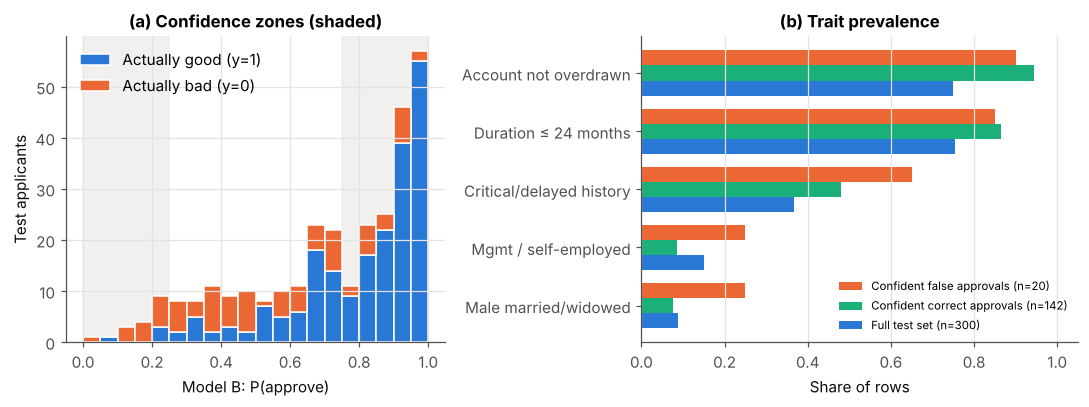

In [14]:
# Figure 4 – distribution of confidence and where the confident errors sit
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8), gridspec_kw={"width_ratios": [1, 1.15]})
ax = axes[0]; binsx = np.linspace(0, 1, 21)
ax.hist([te.p[te.approve == 1], te.p[te.approve == 0]], bins=binsx, stacked=True, color=[C1, C2],
        label=["Actually good (y=1)", "Actually bad (y=0)"], edgecolor="white", linewidth=1)
ax.axvspan(.75, 1, color=GRID, alpha=.5, zorder=0); ax.axvspan(0, .25, color=GRID, alpha=.5, zorder=0)
ax.set_xlabel("Model B: P(approve)"); ax.set_ylabel("Test applicants"); ax.set_title("(a) Confidence zones (shaded)"); ax.legend(loc="upper left")
ax = axes[1]
show = ["checking account not overdrawn (status ≠ <0 DM)", "loan duration ≤ 24 months", "credit history critical or delayed",
        "job: management / self-employed / highly qualified", "male, married/widowed"]
short = ["Account not overdrawn", "Duration ≤ 24 months", "Critical/delayed history", "Mgmt / self-employed", "Male married/widowed"]
yy = np.arange(len(show)); h = .26
ax.barh(yy - h, tt.loc[show, "conf. false approvals"], h, color=C2, label=f"Confident false approvals (n={int(cfp.sum())})")
ax.barh(yy, tt.loc[show, "conf. correct approvals"], h, color=C3, label=f"Confident correct approvals (n={int(ctp.sum())})")
ax.barh(yy + h, tt.loc[show, "full test set"], h, color=C1, label="Full test set (n=300)")
ax.set_yticks(yy); ax.set_yticklabels(short); ax.invert_yaxis(); ax.set_xlim(0, 1.05); ax.set_xlabel("Share of rows")
ax.set_title("(b) Trait prevalence"); ax.legend(loc="lower right", fontsize=7.5); ax.grid(axis="y", visible=False)
fig.tight_layout(); fig.savefig("figures/fig4_adversarial.png"); plt.show()

## 6. Part 2.4 — Fairness trade-off sweep

**Sensitive variable:** age group. **Group A = young (≤ 25)**, **Group B = older (> 25)**, on the 300-row test set.
Decision rule at threshold *t*: Ŷ = 1 (approve) if P ≥ t, for t ∈ {0.05, 0.15, …, 0.95}.

* DP = P(Ŷ=1 | A) / P(Ŷ=1 | B)
* EO = min(TPR_A / TPR_B, FPR_A / FPR_B)
* PP = P(Y=1 | Ŷ=1, A) / P(Y=1 | Ŷ=1, B)

Ideal value of each ratio is 1.0. Accuracy and the UCI-documented misclassification cost (approving a bad risk costs 5,
rejecting a good risk costs 1) are reported alongside. A ratio is left blank if its denominator is 0.

In [15]:
gA = (te.young == 1).values; gB = ~gA; yv = te.approve.values; pv = te.p.values
THRESH = np.round(np.arange(0.05, 1.0, 0.10), 2)
def rate(num, den): return num.sum() / den.sum() if den.sum() > 0 else np.nan
def group_stats(yh, g):
    return {"sel": rate(yh[g] == 1, g[g]), "tpr": rate((yh == 1) & (yv == 1) & g, (yv == 1) & g),
            "fpr": rate((yh == 1) & (yv == 0) & g, (yv == 0) & g), "ppv": rate((yv == 1) & (yh == 1) & g, (yh == 1) & g)}
def ratio(a, b): return a / b if (b is not None and not np.isnan(b) and b > 0 and not np.isnan(a)) else np.nan
rows = []
for t in THRESH:
    yh = (pv >= t).astype(int); A, B = group_stats(yh, gA), group_stats(yh, gB)
    tpr_r, fpr_r = ratio(A["tpr"], B["tpr"]), ratio(A["fpr"], B["fpr"])
    rows.append({"t": t, "DP": ratio(A["sel"], B["sel"]), "TPR_ratio": tpr_r, "FPR_ratio": fpr_r,
                 "EO": np.nanmin([tpr_r, fpr_r]) if not (np.isnan(tpr_r) and np.isnan(fpr_r)) else np.nan,
                 "PP": ratio(A["ppv"], B["ppv"]), "accuracy": (yh == yv).mean(),
                 "cost_per_applicant": (5 * ((yh == 1) & (yv == 0)).sum() + ((yh == 0) & (yv == 1)).sum()) / len(yv),
                 "sel_A": A["sel"], "sel_B": B["sel"], "TPR_A": A["tpr"], "TPR_B": B["tpr"], "FPR_A": A["fpr"], "FPR_B": B["fpr"],
                 "PPV_A": A["ppv"], "PPV_B": B["ppv"]})
sweep = pd.DataFrame(rows)
sweep["all_three_within_0.8_1.25"] = sweep[["DP", "EO", "PP"]].apply(lambda s: bool(((s >= .8) & (s <= 1.25)).all()), axis=1)
sweep.round(4).to_csv("results/p24_sweep.csv", index=False)
R["p24"] = {"nA": int(gA.sum()), "nB": int(gB.sum()), "nA_pos": int(((yv == 1) & gA).sum()), "nA_neg": int(((yv == 0) & gA).sum()),
            "baseA": r(yv[gA].mean()), "baseB": r(yv[gB].mean()),
            "sweep": [{k: (r(v, 4) if isinstance(v, (float, np.floating)) else v) for k, v in row.items()} for row in sweep.to_dict("records")]}
sweep.round(3)

,t,DP,TPR_ratio,FPR_ratio,EO,PP,accuracy,cost_per_applicant,sel_A,sel_B,TPR_A,TPR_B,FPR_A,FPR_B,PPV_A,PPV_B,all_three_within_0.8_1.25
0,0.05,1.004,1.000,1.016,1.000,0.727,0.703,1.483,1.000,0.996,1.000,1.000,1.000,0.984,0.541,0.744,False
1,0.15,1.021,1.006,1.069,1.006,0.719,0.710,1.437,1.000,0.979,1.000,0.994,1.000,0.935,0.541,0.752,False
2,0.25,0.971,1.023,0.961,0.961,0.770,0.733,1.280,0.918,0.946,1.000,0.977,0.821,0.855,0.589,0.765,False
3,0.35,0.907,0.952,0.942,0.942,0.767,0.740,1.153,0.820,0.904,0.909,0.955,0.714,0.758,0.600,0.782,False
4,0.45,0.877,0.905,1.076,0.905,0.753,0.773,0.920,0.738,0.841,0.848,0.938,0.607,0.565,0.622,0.826,False
5,0.55,0.859,0.917,1.069,0.917,0.779,0.773,0.800,0.672,0.782,0.818,0.893,0.500,0.468,0.659,0.845,False
6,0.65,0.853,0.942,1.107,0.942,0.807,0.770,0.670,0.607,0.711,0.788,0.836,0.393,0.355,0.703,0.871,True
7,0.75,0.749,0.931,0.738,0.738,0.908,0.707,0.560,0.426,0.569,0.636,0.684,0.179,0.242,0.808,0.890,False
8,0.85,0.520,0.677,0.443,0.443,0.951,0.647,0.513,0.246,0.473,0.394,0.582,0.071,0.161,0.867,0.912,False
9,0.95,0.218,0.202,2.214,0.202,0.679,0.477,0.550,0.049,0.226,0.061,0.299,0.036,0.016,0.667,0.981,False


In [16]:
# Quantify the DP–EO trade-off: every pair of thresholds where DP moves toward 1 while EO moves away from 1
def dist(v): return abs(1 - v)
pairs = []
for i, a in sweep.iterrows():
    for j, b in sweep.iterrows():
        if i == j: continue
        if dist(b.DP) < dist(a.DP) and dist(b.EO) > dist(a.EO):
            Z = 100 * (b.DP - a.DP) / a.DP; W = 100 * (a.EO - b.EO) / a.EO
            pairs.append({"from_t": a.t, "to_t": b.t, "DP_from": a.DP, "DP_to": b.DP, "Z_dp_gain_pct": Z,
                          "EO_from": a.EO, "EO_to": b.EO, "W_eo_loss_pct": W, "cost_W_over_Z": W / Z if Z != 0 else np.nan,
                          "adjacent": abs(a.t - b.t) < 0.11})
tradeoff = pd.DataFrame(pairs).sort_values(["adjacent", "from_t"], ascending=[False, True])
tradeoff.round(4).to_csv("results/p24_tradeoff_pairs.csv", index=False)
R["p24"]["tradeoff_pairs"] = [{k: (r(v, 4) if isinstance(v, (float, np.floating)) else v) for k, v in row.items()} for row in tradeoff.to_dict("records")]

# DP vs PP: the dominant conflict in this data
s = sweep.set_index("t")
R["p24"]["dp_pp"] = {"t_from": 0.85, "t_to": 0.65, "DP_from": r(s.loc[0.85, "DP"]), "DP_to": r(s.loc[0.65, "DP"]),
                     "PP_from": r(s.loc[0.85, "PP"]), "PP_to": r(s.loc[0.65, "PP"]),
                     "Z": r(100 * (s.loc[0.65, "DP"] - s.loc[0.85, "DP"]) / s.loc[0.85, "DP"], 1),
                     "W": r(100 * (s.loc[0.85, "PP"] - s.loc[0.65, "PP"]) / s.loc[0.85, "PP"], 1)}
R["p24"]["dp_pp"]["cost"] = r(R["p24"]["dp_pp"]["W"] / R["p24"]["dp_pp"]["Z"], 3)
R["p24"]["t_max_acc"] = float(s.accuracy.idxmax()); R["p24"]["max_acc"] = r(s.accuracy.max())
R["p24"]["t_min_cost"] = float(s.cost_per_applicant.idxmin()); R["p24"]["min_cost"] = r(s.cost_per_applicant.min())
R["p24"]["t_all_three_ok"] = [float(t) for t in sweep.loc[sweep["all_three_within_0.8_1.25"], "t"]]
R["p24"]["bayes_threshold_cost_5_1"] = r(5 / 6, 3)
print(tradeoff[tradeoff.adjacent].round(3)); print(R["p24"]["dp_pp"], R["p24"]["t_all_three_ok"], R["p24"]["t_min_cost"])

   from_t  to_t  DP_from  DP_to  Z_dp_gain_pct  EO_from  EO_to  W_eo_loss_pct  cost_W_over_Z  adjacent
0    0.55  0.45    0.859  0.877          2.111    0.917  0.905          1.294          0.613      True
3    0.65  0.55    0.853  0.859          0.737    0.942  0.917          2.726          3.699      True
{'t_from': 0.85, 't_to': 0.65, 'DP_from': 0.52, 'DP_to': 0.853, 'PP_from': 0.951, 'PP_to': 0.807, 'Z': 64.0, 'W': 15.1, 'cost': 0.236} [0.65] 0.85


In [17]:
# Bootstrap 95% intervals for the metrics at the recommended threshold t = 0.65 (and at 0.85 for contrast)
rng = np.random.default_rng(SEED); B_ = 2000
def metrics_at(t, idx):
    yh = (pv[idx] >= t).astype(int); yy_ = yv[idx]; ga = gA[idx]; gb = ~ga
    def rt(num, den): return num.sum() / den.sum() if den.sum() > 0 else np.nan
    sA, sB = rt(yh[ga] == 1, ga[ga]), rt(yh[gb] == 1, gb[gb])
    tA, tB = rt((yh == 1) & (yy_ == 1) & ga, (yy_ == 1) & ga), rt((yh == 1) & (yy_ == 1) & gb, (yy_ == 1) & gb)
    fA, fB = rt((yh == 1) & (yy_ == 0) & ga, (yy_ == 0) & ga), rt((yh == 1) & (yy_ == 0) & gb, (yy_ == 0) & gb)
    qA, qB = rt((yy_ == 1) & (yh == 1) & ga, (yh == 1) & ga), rt((yy_ == 1) & (yh == 1) & gb, (yh == 1) & gb)
    return sA / sB, np.nanmin([tA / tB, fA / fB]), qA / qB
boot = {}
for t in (0.65, 0.85):
    sims = np.array([metrics_at(t, rng.integers(0, len(pv), len(pv))) for _ in range(B_)])
    lo, hi = np.nanpercentile(sims, [2.5, 97.5], axis=0)
    boot[str(t)] = {m: [r(lo[k]), r(hi[k])] for k, m in enumerate(["DP", "EO", "PP"])}
R["p24"]["bootstrap_ci"] = boot; print(boot)

# Group-specific threshold that would equalise approval rates when older applicants face t = 0.85 (illustration for Q6)
selB85 = s.loc[0.85, "sel_B"]; grid = np.round(np.arange(0.50, 0.851, 0.01), 2)
selA_grid = np.array([(pv[gA] >= t).mean() for t in grid]); tA_eq = float(grid[np.argmin(abs(selA_grid - selB85))])
yhA = (pv[gA] >= tA_eq); R["p24"]["dp_fix"] = {"tB": 0.85, "tA": tA_eq, "selA": r(yhA.mean()), "selB": r(selB85),
    "FPR_A": r((yhA & (yv[gA] == 0)).sum() / (yv[gA] == 0).sum()), "TPR_A": r((yhA & (yv[gA] == 1)).sum() / (yv[gA] == 1).sum()),
    "PPV_A": r(yv[gA][yhA].mean()), "n_bad_young_approved": int((yhA & (yv[gA] == 0)).sum()),
    "n_bad_young_approved_at_085": int(((pv[gA] >= .85) & (yv[gA] == 0)).sum())}
print(R["p24"]["dp_fix"])

{'0.65': {'DP': [0.667, 1.046], 'EO': [0.579, 1.101], 'PP': [0.624, 0.973]}, '0.85': {'DP': [0.296, 0.769], 'EO': [0.0, 0.839], 'PP': [0.732, 1.131]}}
{'tB': 0.85, 'tA': 0.71, 'selA': 0.475, 'selB': 0.473, 'FPR_A': 0.286, 'TPR_A': 0.636, 'PPV_A': 0.724, 'n_bad_young_approved': 8, 'n_bad_young_approved_at_085': 2}


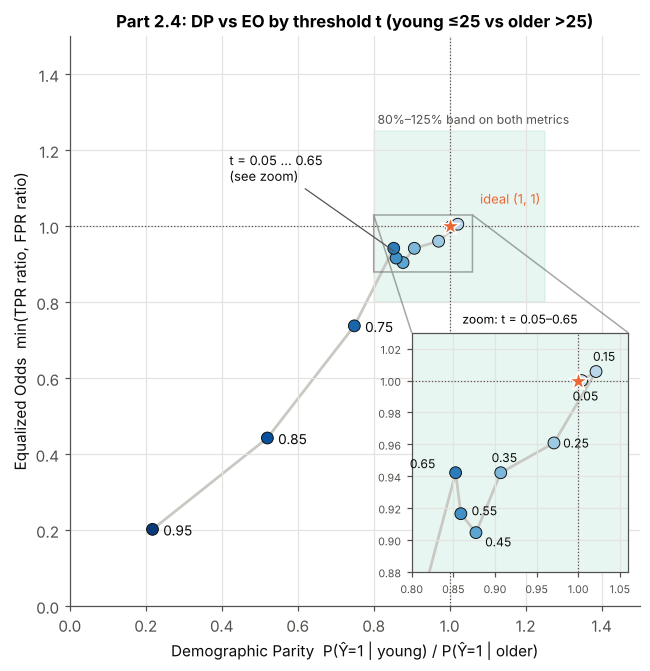

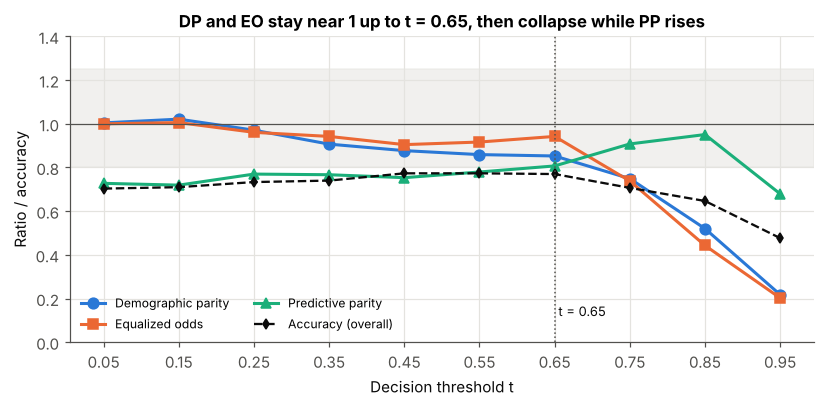

In [18]:
# Figure 5 – the trade-off chart required by the brief (DP on x, EO on y, both 0–1.5, labelled by threshold)
fig, ax = plt.subplots(figsize=(7.0, 6.2))
def draw(ax_, labels_offsets, fs):
    ax_.add_patch(plt.Rectangle((0.8, 0.8), 0.45, 0.45, color=C3, alpha=.10, zorder=0))
    ax_.plot(sweep.DP, sweep.EO, color="#c9c8c3", lw=1.8, zorder=1)
    ax_.scatter(sweep.DP, sweep.EO, s=60, c=sweep.t, cmap="Blues", vmin=-.2, vmax=1.0, edgecolor=INK, linewidth=.6, zorder=3)
    ax_.scatter([1], [1], marker="*", s=170, color=C2, zorder=4, edgecolor="white")
    ax_.axvline(1, color=MUTED, lw=.8, ls=":"); ax_.axhline(1, color=MUTED, lw=.8, ls=":")
    for _, rw in sweep.iterrows():
        off = labels_offsets.get(round(rw.t, 2))
        if off is not None:
            ax_.annotate(f"{rw.t:.2f}", (rw.DP, rw.EO), xytext=off, textcoords="offset points", fontsize=fs, color=INK)
draw(ax, {0.75: (7, -4), 0.85: (7, -4), 0.95: (7, -4)}, 9)
ax.text(0.81, 1.27, "80%–125% band on both metrics", fontsize=8, color=MUTED)
ax.annotate("t = 0.05 … 0.65\n(see zoom)", (0.86, 0.93), xytext=(0.42, 1.12), fontsize=8.5, color=INK,
            arrowprops=dict(arrowstyle="-", color=MUTED, lw=.8))
ax.annotate("ideal (1, 1)", (1, 1), xytext=(1.08, 1.06), fontsize=8.5, color=C2)
ax.set_xlim(0, 1.5); ax.set_ylim(0, 1.5); ax.set_aspect("equal")
ax.set_xlabel("Demographic Parity  P(Ŷ=1 | young) / P(Ŷ=1 | older)"); ax.set_ylabel("Equalized Odds  min(TPR ratio, FPR ratio)")
ax.set_title("Part 2.4: DP vs EO by threshold t (young ≤25 vs older >25)")
ins = ax.inset_axes([0.60, 0.06, 0.38, 0.42])
draw(ins, {0.05: (-6, -13), 0.15: (-2, 7), 0.25: (6, -3), 0.35: (-6, 7), 0.45: (6, -9), 0.55: (7, -1), 0.65: (-30, 3)}, 8)
ins.set_xlim(0.80, 1.06); ins.set_ylim(0.88, 1.03); ins.tick_params(labelsize=7); ins.set_title("zoom: t = 0.05–0.65", fontsize=8, fontweight="normal")
for sp in ins.spines.values(): sp.set_visible(True); sp.set_color(MUTED)
ax.indicate_inset_zoom(ins, edgecolor=MUTED)
fig.tight_layout(); fig.savefig("figures/fig5_tradeoff.png"); plt.show()

# Figure 6 – all three metrics and accuracy against the threshold
fig, ax = plt.subplots(figsize=(7.6, 3.8))
for col, c, lab, mk in [("DP", C1, "Demographic parity", "o"), ("EO", C2, "Equalized odds", "s"), ("PP", C3, "Predictive parity", "^")]:
    ax.plot(sweep.t, sweep[col], marker=mk, ms=7, lw=2, color=c, label=lab)
ax.plot(sweep.t, sweep.accuracy, color=INK, lw=1.5, ls="--", marker="d", ms=5, label="Accuracy (overall)")
ax.axhspan(.8, 1.25, color=GRID, alpha=.5, zorder=0); ax.axhline(1, color=MUTED, lw=.8)
ax.axvline(0.65, color=MUTED, lw=1, ls=":"); ax.text(0.655, 0.12, "t = 0.65", fontsize=8.5, color=INK)
ax.set_xticks(THRESH); ax.set_ylim(0, 1.4); ax.set_xlabel("Decision threshold t"); ax.set_ylabel("Ratio / accuracy")
ax.set_title("DP and EO stay near 1 up to t = 0.65, then collapse while PP rises"); ax.legend(loc="lower left", ncol=2, fontsize=8)
fig.tight_layout(); fig.savefig("figures/fig6_metrics_vs_threshold.png"); plt.show()

## 7. Export results
All values used in the PDF report are written here.

In [19]:
def clean(o):
    if isinstance(o, dict): return {str(k): clean(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)): return [clean(v) for v in o]
    if isinstance(o, (np.integer,)): return int(o)
    if isinstance(o, (np.floating, float)): return None if np.isnan(o) else float(o)
    if isinstance(o, (np.bool_,)): return bool(o)
    return o
json.dump(clean(R), open("results/results.json", "w"), indent=1, ensure_ascii=False)
print("saved results/results.json with", len(R), "top-level keys;", sorted(os.listdir("figures")))

saved results/results.json with 32 top-level keys; ['fig1_threshold_scatter.png', 'fig2_simpson.png', 'fig3_ovb.png', 'fig4_adversarial.png', 'fig5_tradeoff.png', 'fig6_metrics_vs_threshold.png']
